
# Building an Agentic RAG for Financial Document Analysis



**Project:** Financial Document Analysis Agent

**Knowledge Sources:** Apple Inc. Annual Reports (Form 10-K), Fiscal Years 2023, 2024, and 2025



---

## Introduction

This project develops an Agentic Retrieval-Augmented Generation (RAG) system for analysing financial information from Apple's annual reports.

The system combines document processing, semantic search, a language model, Python-based financial calculations, and agent orchestration to answer financial questions using evidence retrieved from the supplied documents.

Rather than relying solely on information learned during language-model training, the system retrieves relevant passages from the annual reports and uses that evidence to support its analysis.


## Section 1: Installing and Loading Relevant Libraries

This section prepares the Google Colab environment by installing and importing the libraries required for PDF processing, semantic retrieval, language-model inference, agent orchestration, financial calculations, visualisation, and report generation.


In [1]:
!pip install -q pymupdf sentence-transformers faiss-cpu transformers accelerate langgraph matplotlib fpdf2

In [2]:
import os
import re
from typing import TypedDict, List, Dict, Any

import fitz  # PyMuPDF
import numpy as np
import faiss
import torch
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM
from langgraph.graph import StateGraph, END
from fpdf import FPDF, XPos, YPos

print("All required libraries imported successfully.")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


All required libraries imported successfully.
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


## Section 2: Document Processing and Text Chunking

This section locates Apple Inc.'s FY2023–FY2025 Form 10-K PDF filings, extracts text page by page using PyMuPDF while preserving document metadata (`source`, `year`, `page`), and splits the extracted text into overlapping 220-word chunks with a 40-word overlap for semantic retrieval.

In [3]:
import glob

SEARCH_DIRS = ["/content/sample_data", "/content"]
OUTPUT_DIR = "/content"
os.makedirs(OUTPUT_DIR, exist_ok=True)

PDF_FILES = {}
for folder in SEARCH_DIRS:
    for path in sorted(glob.glob(os.path.join(folder, "*10-K*.pdf"))):
        match = re.search(r"(202[3-5])", os.path.basename(path))
        if match:
            yr = int(match.group(1))
            PDF_FILES.setdefault(yr, path)

for yr in (2023, 2024, 2025):
    if yr not in PDF_FILES:
        raise FileNotFoundError(f"Missing FY{yr} 10-K PDF in {SEARCH_DIRS}")
    print(f"FY{yr} FOUND: {PDF_FILES[yr]}")

FY2023 FOUND: /content/sample_data/_10-K-2023-As-Filed.pdf
FY2024 FOUND: /content/sample_data/10-K-2024-As-Filed.pdf
FY2025 FOUND: /content/sample_data/_10-K-2025-As-Filed.pdf


In [4]:
def load_pdf_pages(pdf_files: Dict[int, str]) -> List[Dict[str, Any]]:
    pages = []
    for year, pdf_path in sorted(pdf_files.items()):
        doc = fitz.open(pdf_path)
        source_name = os.path.basename(pdf_path)
        for page_num in range(len(doc)):
            text = doc[page_num].get_text("text").strip()
            if text:
                pages.append({
                    "text": text,
                    "page": page_num + 1,
                    "year": year,
                    "source": source_name,
                })
        doc.close()
    return pages


def chunk_text(text: str, chunk_size: int = 220, overlap: int = 40) -> List[str]:
    words = text.split()
    result = []
    start = 0
    while start < len(words):
        chunk = " ".join(words[start:start + chunk_size])
        if chunk.strip():
            result.append(chunk)
        start += chunk_size - overlap
    return result


pages = load_pdf_pages(PDF_FILES)
print(f"Loaded {len(pages)} non-empty pages across {len(PDF_FILES)} filings.")

chunks = []
for p in pages:
    for c in chunk_text(p["text"], chunk_size=220, overlap=40):
        chunks.append({
            "text": c,
            "page": p["page"],
            "year": p["year"],
            "source": p["source"],
        })

print(f"Created {len(chunks)} text chunks.")
print("Sample chunk metadata:", {k: chunks[0][k] for k in ("source", "year", "page")})

Loaded 281 non-empty pages across 3 filings.
Created 958 text chunks.
Sample chunk metadata: {'source': '_10-K-2023-As-Filed.pdf', 'year': 2023, 'page': 1}


## Section 3: Semantic Retrieval (Embeddings and FAISS Index)

This section encodes all 958 document chunks into dense vector embeddings using the `all-MiniLM-L6-v2` SentenceTransformer model and stores them in a normalized `faiss.IndexFlatIP` vector index for cosine-similarity semantic search.

In [5]:
EMBED_MODEL_NAME = "all-MiniLM-L6-v2"
embedder = SentenceTransformer(EMBED_MODEL_NAME)

chunk_texts = [c["text"] for c in chunks]
embeddings = embedder.encode(
    chunk_texts,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True,
)
embeddings = np.array(embeddings, dtype="float32")

dim = embeddings.shape[1]
index = faiss.IndexFlatIP(dim)
index.add(embeddings)

print(f"FAISS index built with {index.ntotal} vectors (dim={dim}).")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

FAISS index built with 958 vectors (dim=384).


## Section 4: Loading the Local LLM (`Qwen/Qwen2.5-1.5B-Instruct`)

This section loads the `Qwen/Qwen2.5-1.5B-Instruct` open-weights language model onto the Colab GPU and defines the `generate_with_qwen` helper function used by the agent planner and report generator.

In [6]:
QWEN_MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(QWEN_MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    QWEN_MODEL_ID,
    torch_dtype="auto",
    device_map="auto",
)
model.eval()


def generate_with_qwen(
    prompt: str,
    system_prompt: str = "You are a helpful financial analysis assistant.",
    max_new_tokens: int = 300,
) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": prompt},
    ]
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    inputs = tokenizer([text], return_tensors="pt").to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )
    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated_ids, skip_special_tokens=True).strip()


print("Loaded LLM:", QWEN_MODEL_ID)
print("Sanity test:", generate_with_qwen("Reply with the single word READY.", max_new_tokens=10))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loaded LLM: Qwen/Qwen2.5-1.5B-Instruct
Sanity test: READY


## Section 5: Financial Retrieval Tools

This section implements the semantic retrieval tools (`retrieve_financial_info`, `financial_retrieval_tool`, and `retrieve_within_year`) adapted from the reference Medical Document Agent to query the FAISS index and return relevant Apple Form 10-K passages with source, fiscal year, and page citations.

In [7]:
def retrieve_financial_info(query: str, k: int = 5) -> List[Dict[str, Any]]:
    query_vec = embedder.encode([query], normalize_embeddings=True)
    query_vec = np.array(query_vec, dtype="float32")
    scores, indices = index.search(query_vec, k)

    results = []
    for score, idx in zip(scores[0], indices[0]):
        item = dict(chunks[idx])
        item["score"] = float(score)
        results.append(item)
    return results


def financial_retrieval_tool(query: str, k: int = 5) -> str:
    results = retrieve_financial_info(query, k=k)
    blocks = []
    for r in results:
        blocks.append(f"[{r['source']} ({r['year']}) p.{r['page']}]\n{r['text']}")
    return "\n\n".join(blocks)


def retrieve_within_year(query: str, year: int, k: int = 5) -> List[Dict[str, Any]]:
    year_indices = [i for i, c in enumerate(chunks) if c["year"] == year]
    if not year_indices:
        return []
    year_embeddings = embeddings[year_indices]
    query_vec = embedder.encode([query], normalize_embeddings=True)
    query_vec = np.array(query_vec, dtype="float32")
    scores = np.dot(year_embeddings, query_vec[0])
    top_local = np.argsort(scores)[::-1][:k]

    results = []
    for loc in top_local:
        item = dict(chunks[year_indices[loc]])
        item["score"] = float(scores[loc])
        results.append(item)
    return results


# Quick retrieval test
sample_hits = retrieve_financial_info("Apple total net sales 2025 2024 2023", k=3)
for h in sample_hits:
    print(f"[{h['source']} ({h['year']}) p.{h['page']}] score={h['score']:.3f}")

[_10-K-2023-As-Filed.pdf (2023) p.25] score=0.821
[10-K-2024-As-Filed.pdf (2024) p.26] score=0.773
[_10-K-2023-As-Filed.pdf (2023) p.38] score=0.749


## Section 6: Financial Extraction and Python Calculation Tools

This section defines the evidence-based regex extractors for Apple's FY2025 Form 10-K financial tables and the Python calculation tools (`calculate_percent_change`, `calculate_category_shares`, and `compare_segment_growth`) so that all numerical analysis is computed accurately in Python rather than by the LLM.

In [8]:
def _candidate_2025_chunks(evidence: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
    seen = set()
    ordered = []
    for item in list(evidence) + [c for c in chunks if c["year"] == 2025]:
        if item["year"] != 2025:
            continue
        key = (item["source"], item["page"], item["text"][:60])
        if key not in seen:
            seen.add(key)
            ordered.append(item)
    return ordered


def extract_total_net_sales(evidence: List[Dict[str, Any]]) -> Dict[str, Any]:
    """Extract FY2023, FY2024, and FY2025 Total Net Sales (USD millions) from Apple's FY2025 10-K."""
    pattern = (
        r"Total\s+net\s+sales\s+\$?\s*([\d,]+)"
        r"(?:\s+\(?[\d,]+\)?\s*%)?"
        r"\s+\$?\s*([\d,]+)"
        r"(?:\s+\(?[\d,]+\)?\s*%)?"
        r"\s+\$?\s*([\d,]+)"
    )
    for item in _candidate_2025_chunks(evidence):
        match = re.search(pattern, item["text"], re.IGNORECASE)
        if not match:
            continue
        vals = [int(v.replace(",", "")) for v in match.groups()]
        if len(vals) == 3 and all(v > 100000 for v in vals):
            return {
                2025: vals[0],
                2024: vals[1],
                2023: vals[2],
                "source": item["source"],
                "page": item["page"],
            }
    raise ValueError("Could not extract Total Net Sales (2023-2025) from the FY2025 10-K.")


def extract_product_category_revenues(evidence: List[Dict[str, Any]]) -> Dict[str, Any]:
    """Extract FY2025 Net Sales by product category (USD millions) from Apple's FY2025 10-K."""
    category_patterns = {
        "iPhone": r"\biPhone\s+\$?\s*([\d,]+)",
        "Mac": r"\bMac\s+\$?\s*([\d,]+)",
        "iPad": r"\biPad\s+\$?\s*([\d,]+)",
        "Wearables, Home and Accessories": r"Wearables,\s*Home\s+and\s+Accessories\s+\$?\s*([\d,]+)",
        "Services": r"\bServices\s*(?:\(1\))?\s+\$?\s*([\d,]+)",
    }
    for item in _candidate_2025_chunks(evidence):
        text = item["text"]
        if "net sales by category" not in text.lower() or "total net sales" not in text.lower():
            continue
        revenues = {}
        for cat, pat in category_patterns.items():
            m = re.search(pat, text, re.IGNORECASE)
            if m:
                revenues[cat] = int(m.group(1).replace(",", ""))
        if len(revenues) == len(category_patterns):
            return {
                "categories": revenues,
                "total": sum(revenues.values()),
                "source": item["source"],
                "page": item["page"],
            }
    raise ValueError("Could not extract FY2025 product category revenues from the FY2025 10-K.")


def extract_products_services_revenue(evidence: List[Dict[str, Any]]) -> Dict[str, Any]:
    """Extract Products and Services Net Sales (FY2023-FY2025, USD millions) from the Consolidated Statements of Operations."""
    pattern = (
        r"Net\s+sales:\s*"
        r"Products\s+\$?\s*([\d,]+)\s+\$?\s*([\d,]+)\s+\$?\s*([\d,]+)\s+"
        r"Services\s+\$?\s*([\d,]+)\s+\$?\s*([\d,]+)\s+\$?\s*([\d,]+)"
    )
    for item in _candidate_2025_chunks(evidence):
        m = re.search(pattern, item["text"], re.IGNORECASE)
        if m:
            vals = [int(v.replace(",", "")) for v in m.groups()]
            return {
                "products_2025": vals[0],
                "products_2024": vals[1],
                "products_2023": vals[2],
                "services_2025": vals[3],
                "services_2024": vals[4],
                "services_2023": vals[5],
                "source": item["source"],
                "page": item["page"],
            }
    raise ValueError("Could not extract Products and Services net sales from the FY2025 10-K.")


def calculate_percent_change(value_old: float, value_new: float) -> Dict[str, float]:
    """Compute absolute and percentage change (same return schema as Medical_doc_Agent)."""
    if value_old == 0:
        raise ValueError("value_old cannot be zero.")
    abs_change = value_new - value_old
    pct_change = (abs_change / value_old) * 100.0
    return {
        "old": value_old,
        "new": value_new,
        "absolute_change": round(abs_change, 2),
        "percent_change": round(pct_change, 2),
    }


def calculate_category_shares(category_revenues: Dict[str, int]) -> Dict[str, Any]:
    """Compute each product category's share (%) of total net sales and find the top contributor."""
    total = sum(category_revenues.values())
    shares = {cat: round((val / total) * 100.0, 2) for cat, val in category_revenues.items()}
    ranked = sorted(category_revenues.items(), key=lambda kv: kv[1], reverse=True)
    top_category, top_revenue = ranked[0]
    return {
        "total": total,
        "revenues": dict(ranked),
        "shares": {cat: shares[cat] for cat, _ in ranked},
        "top_category": top_category,
        "top_revenue": top_revenue,
        "top_share": shares[top_category],
    }


def compare_segment_growth(segment_data: Dict[str, Any]) -> Dict[str, Any]:
    """Compare FY2024-to-FY2025 revenue growth of Products vs. Services."""
    products_calc = calculate_percent_change(segment_data["products_2024"], segment_data["products_2025"])
    services_calc = calculate_percent_change(segment_data["services_2024"], segment_data["services_2025"])
    if services_calc["percent_change"] > products_calc["percent_change"]:
        faster = "Services"
    elif products_calc["percent_change"] > services_calc["percent_change"]:
        faster = "Products"
    else:
        faster = "Tie"
    return {
        "products": products_calc,
        "services": services_calc,
        "faster_segment": faster,
    }


# Quick test on all three extractors and calculators
_test_ev = retrieve_financial_info("Apple total net sales by category Products Services 2025 2024 2023", k=8)
_sales = extract_total_net_sales(_test_ev)
_cats = extract_product_category_revenues(_test_ev)
_segs = extract_products_services_revenue(_test_ev)

print("Q1 Check:", calculate_percent_change(_sales[2023], _sales[2025]), f"(Source: {_sales['source']} p.{_sales['page']})")
_q2 = calculate_category_shares(_cats["categories"])
print(f"Q2 Check: {_q2['top_category']} (${_q2['top_revenue']:,}M, {_q2['top_share']}%) (Source: {_cats['source']} p.{_cats['page']})")
print("Q3 Check:", compare_segment_growth(_segs), f"(Source: {_segs['source']} p.{_segs['page']})")

Q1 Check: {'old': 383285, 'new': 416161, 'absolute_change': 32876, 'percent_change': 8.58} (Source: _10-K-2025-As-Filed.pdf p.26)
Q2 Check: iPhone ($209,586M, 50.36%) (Source: _10-K-2025-As-Filed.pdf p.26)
Q3 Check: {'products': {'old': 294866, 'new': 307003, 'absolute_change': 12137, 'percent_change': 4.12}, 'services': {'old': 96169, 'new': 109158, 'absolute_change': 12989, 'percent_change': 13.51}, 'faster_segment': 'Services'} (Source: _10-K-2025-As-Filed.pdf p.32)


## Section 7: Report Generation Tool

This section defines `generate_full_financial_report`, which mirrors the reference Medical Document Agent's report tool by prompting `Qwen/Qwen2.5-1.5B-Instruct` to write a concise two-paragraph plain-text narrative grounded strictly in the Python calculation outputs and retrieved Form 10-K evidence.

In [9]:
def generate_full_financial_report(
    question: str,
    calc_summary: str,
    matched_evidence: str,
) -> str:
    prompt = f"""Write a concise, strictly factual 2-paragraph financial analysis answering the question below.

Question: {question}

Verified Python Calculation Results:
{calc_summary}

Direct Form 10-K Evidence Excerpt:
{matched_evidence[:1000]}

Strict Rules:
- Write 2 short paragraphs in plain text (no #, *, -, or bullet lists).
- Use ONLY the exact dollar amounts, percentages, and fiscal years shown in "Verified Python Calculation Results" above.
- Do NOT introduce, estimate, or compute any other dollar amounts or percentages.
- Explicitly cite the Form 10-K filename and PDF page number from the verified results above.
"""
    raw = generate_with_qwen(
        prompt,
        system_prompt="You are a strict financial analyst. Only repeat verified numbers provided in the prompt.",
        max_new_tokens=260,
    )
    return re.sub(r"[#*`]+", "", raw).strip()

## Section 8: LangGraph Agentic Workflow (State, Planner, Action Nodes and Routing)

This section implements the LangGraph agentic loop adapted from the Medical Document Agent, defining `AgentState`, an LLM-driven `planner_node` powered by `Qwen/Qwen2.5-1.5B-Instruct`, three action nodes (`retrieve_node`, `calculate_node`, and `report_node`), and conditional routing that iterates back to the planner until `FINISH` terminates execution.

In [10]:
class AgentState(TypedDict):
    question: str
    task_type: str
    retrieved_context: str
    retrieved_chunks: List[Dict[str, Any]]
    values_by_year: Dict[Any, Any]
    calc_result: Dict[str, Any]
    numbers_found: bool
    report: str
    next_action: str
    steps_done: List[str]


def infer_task_type(question: str) -> str:
    q = question.lower()
    if "product category" in q or "contributed the most" in q or "category" in q:
        return "top_category"
    if "products" in q and "services" in q:
        return "segment_growth"
    return "total_revenue"


def _find_exact_chunk(source: str, page: int, fallback_list: List[Dict[str, Any]]) -> Dict[str, Any]:
    for kw in ("total net sales", "consolidated statements of operations", "net sales"):
        for c in chunks:
            if c["source"] == source and c["page"] == page and kw in c["text"].lower():
                return c
    for c in chunks:
        if c["source"] == source and c["page"] == page:
            return c
    return fallback_list[0]


def planner_node(state: AgentState) -> Dict[str, Any]:
    steps_done = state.get("steps_done", [])
    has_context = bool(state.get("retrieved_context"))
    has_calc = bool(state.get("calc_result"))
    has_report = bool(state.get("report"))

    prompt = f"""You are the planner for a financial document analysis agent.
Decide the SINGLE next action from: RETRIEVE, CALCULATE, REPORT, FINISH.

Rules:
- If no evidence has been retrieved yet -> RETRIEVE
- If evidence is retrieved but calculations are not done yet -> CALCULATE
- If calculations are done but report is not written yet -> REPORT
- If report is written -> FINISH

Current State:
- Question: {state['question']}
- Steps completed so far: {steps_done}
- Evidence retrieved: {has_context}
- Calculations completed: {has_calc}
- Report written: {has_report}

Reply with ONLY ONE WORD: RETRIEVE, CALCULATE, REPORT, or FINISH."""

    decision = generate_with_qwen(
        prompt,
        system_prompt="You are a strict workflow planner. Output only one action keyword.",
        max_new_tokens=10,
    ).upper()

    action = next(
        (cand for cand in ("RETRIEVE", "CALCULATE", "REPORT", "FINISH") if cand in decision),
        None,
    )

    if not has_context:
        expected = "RETRIEVE"
    elif not has_calc:
        expected = "CALCULATE"
    elif not has_report:
        expected = "REPORT"
    else:
        expected = "FINISH"

    if action != expected:
        action = expected

    print(f"[Planner] LLM raw='{decision}' -> selected='{action}' (steps_done={steps_done})")
    return {"next_action": action}


def retrieve_node(state: AgentState) -> Dict[str, Any]:
    hits = retrieve_financial_info(state["question"], k=8)
    context_str = "\n\n".join(
        f"[{h['source'].lstrip('_')} ({h['year']}) p.{h['page']}]\n{h['text']}" for h in hits
    )
    return {
        "retrieved_chunks": hits,
        "retrieved_context": context_str,
        "steps_done": state.get("steps_done", []) + ["RETRIEVE"],
    }


def calculate_node(state: AgentState) -> Dict[str, Any]:
    task_type = state.get("task_type") or infer_task_type(state["question"])
    evidence = state.get("retrieved_chunks", [])

    if task_type == "total_revenue":
        sales = extract_total_net_sales(evidence)
        pct = calculate_percent_change(sales[2023], sales[2025])
        clean_src = sales["source"].lstrip("_")
        matched = _find_exact_chunk(sales["source"], sales["page"], evidence)
        summary_text = (
            f"Apple Inc. Total Net Sales (USD millions): "
            f"FY2023 = ${sales[2023]:,}M, FY2024 = ${sales[2024]:,}M, FY2025 = ${sales[2025]:,}M. "
            f"Between FY2023 and FY2025, Total Net Sales increased by ${pct['absolute_change']:,.0f}M "
            f"(+{pct['percent_change']:.2f}%). "
            f"Source: {clean_src}, PDF page {sales['page']}."
        )
        return {
            "task_type": task_type,
            "values_by_year": {2023: sales[2023], 2024: sales[2024], 2025: sales[2025]},
            "calc_result": {
                **pct,
                "source": clean_src,
                "page": sales["page"],
                "matched_chunk": matched,
                "summary_text": summary_text,
            },
            "numbers_found": True,
            "steps_done": state.get("steps_done", []) + ["CALCULATE"],
        }

    if task_type == "top_category":
        cat_data = extract_product_category_revenues(evidence)
        shares_info = calculate_category_shares(cat_data["categories"])
        clean_src = cat_data["source"].lstrip("_")
        matched = _find_exact_chunk(cat_data["source"], cat_data["page"], evidence)
        breakdown_str = ", ".join(
            f"{cat}: ${rev:,}M ({shares_info['shares'][cat]:.2f}%)"
            for cat, rev in shares_info["revenues"].items()
        )
        summary_text = (
            f"FY2025 Net Sales by Product Category (Total = ${shares_info['total']:,}M): {breakdown_str}. "
            f"Highest-contributing category in FY2025: {shares_info['top_category']} with "
            f"${shares_info['top_revenue']:,}M ({shares_info['top_share']:.2f}%, more than half of total net sales). "
            f"Source: {clean_src}, PDF page {cat_data['page']}."
        )
        return {
            "task_type": task_type,
            "values_by_year": shares_info["revenues"],
            "calc_result": {
                **shares_info,
                "source": clean_src,
                "page": cat_data["page"],
                "matched_chunk": matched,
                "summary_text": summary_text,
            },
            "numbers_found": True,
            "steps_done": state.get("steps_done", []) + ["CALCULATE"],
        }

    # Q3: Products vs. Services growth (FY2024-FY2025)
    seg_data = extract_products_services_revenue(evidence)
    growth_info = compare_segment_growth(seg_data)
    clean_src = seg_data["source"].lstrip("_")
    matched = _find_exact_chunk(seg_data["source"], seg_data["page"], evidence)
    p = growth_info["products"]
    s = growth_info["services"]
    summary_text = (
        f"From FY2024 to FY2025 (i.e., in FY2025), Products Net Sales increased from ${p['old']:,}M to ${p['new']:,}M "
        f"(+${p['absolute_change']:,.0f}M, +{p['percent_change']:.2f}%), while Services Net Sales increased from "
        f"${s['old']:,}M to ${s['new']:,}M (+${s['absolute_change']:,.0f}M, +{s['percent_change']:.2f}%). "
        f"Faster-growing segment in FY2025: {growth_info['faster_segment']}. "
        f"Source: {clean_src}, PDF page {seg_data['page']}."
    )
    return {
        "task_type": task_type,
        "values_by_year": seg_data,
        "calc_result": {
            **growth_info,
            "source": clean_src,
            "page": seg_data["page"],
            "matched_chunk": matched,
            "summary_text": summary_text,
        },
        "numbers_found": True,
        "steps_done": state.get("steps_done", []) + ["CALCULATE"],
    }


def report_node(state: AgentState) -> Dict[str, Any]:
    mc = state["calc_result"]["matched_chunk"]
    matched_str = f"[{mc['source'].lstrip('_')} ({mc['year']}) p.{mc['page']}]\n{mc['text']}"
    narrative = generate_full_financial_report(
        question=state["question"],
        calc_summary=state["calc_result"]["summary_text"],
        matched_evidence=matched_str,
    )
    return {
        "report": narrative,
        "steps_done": state.get("steps_done", []) + ["REPORT"],
    }


def route_from_planner(state: AgentState) -> str:
    action = state.get("next_action", "FINISH")
    if action in ("RETRIEVE", "CALCULATE", "REPORT"):
        return action
    return END


graph = StateGraph(AgentState)
graph.add_node("planner", planner_node)
graph.add_node("retrieve", retrieve_node)
graph.add_node("calculate", calculate_node)
graph.add_node("report", report_node)

graph.set_entry_point("planner")
graph.add_conditional_edges(
    "planner",
    route_from_planner,
    {
        "RETRIEVE": "retrieve",
        "CALCULATE": "calculate",
        "REPORT": "report",
        END: END,
    },
)
graph.add_edge("retrieve", "planner")
graph.add_edge("calculate", "planner")
graph.add_edge("report", "planner")

agent = graph.compile()
print("LangGraph Financial Document Analysis Agent compiled successfully.")

LangGraph Financial Document Analysis Agent compiled successfully.


## Section 9: Running the Agent on Q1, Q2, and Q3

This section invokes the compiled LangGraph Financial Document Analysis Agent on the two mandatory assignment questions (Q1 and Q2) and our custom financial analysis question (Q3), logging the LLM planner's decisions, the execution trace, the verified Python calculations, and the Qwen-generated narratives.

In [11]:
QUESTIONS = {
    "Q1": {
        "question": "How did the company's total revenue change between 2023 and 2025?",
        "task_type": "total_revenue",
    },
    "Q2": {
        "question": "Which product category contributed the most revenue in the latest year?",
        "task_type": "top_category",
    },
    "Q3": {
        "question": "Compare Apple's Products and Services revenue growth between fiscal years 2024 and 2025. Which grew faster?",
        "task_type": "segment_growth",
    },
}

agent_results = {}

for q_id, cfg in QUESTIONS.items():
    print("=" * 70)
    print(f"{q_id}: {cfg['question']}")
    print("=" * 70)
    initial_state: AgentState = {
        "question": cfg["question"],
        "task_type": cfg["task_type"],
        "retrieved_context": "",
        "retrieved_chunks": [],
        "values_by_year": {},
        "calc_result": {},
        "numbers_found": False,
        "report": "",
        "next_action": "",
        "steps_done": [],
    }
    final_state = agent.invoke(initial_state, config={"recursion_limit": 25})
    agent_results[q_id] = final_state

    print("Execution Trace:", " -> ".join(final_state["steps_done"]) + " -> FINISH")
    print("Verified Calculation:", final_state["calc_result"]["summary_text"])
    print("\nGenerated Report:\n", final_state["report"], "\n")

Q1: How did the company's total revenue change between 2023 and 2025?
[Planner] LLM raw='RETRIEVE' -> selected='RETRIEVE' (steps_done=[])
[Planner] LLM raw='CALCULATE' -> selected='CALCULATE' (steps_done=['RETRIEVE'])
[Planner] LLM raw='REPORT' -> selected='REPORT' (steps_done=['RETRIEVE', 'CALCULATE'])
[Planner] LLM raw='FINISH' -> selected='FINISH' (steps_done=['RETRIEVE', 'CALCULATE', 'REPORT'])
Execution Trace: RETRIEVE -> CALCULATE -> REPORT -> FINISH
Verified Calculation: Apple Inc. Total Net Sales (USD millions): FY2023 = $383,285M, FY2024 = $391,035M, FY2025 = $416,161M. Between FY2023 and FY2025, Total Net Sales increased by $32,876M (+8.58%). Source: 10-K-2025-As-Filed.pdf, PDF page 25.

Generated Report:
 Between 2023 and 2025, Apple Inc.'s total net sales increased significantly. In 2023, the company reported total net sales of $383,285 million. By 2025, this figure had risen to $416,161 million, marking an increase of $32,876 million, or approximately 8.58%. This substanti

## Section 10: Visualisations (Trend Bar Chart and Category Share Pie Chart)

This section generates two visualisations mirroring the reference Medical Document Agent's chart outputs: a bar chart showing Apple Inc.'s Total Net Sales trend from FY2023 to FY2025 (`apple_revenue_trend_chart.png`) and a pie chart illustrating each product category's share of FY2025 revenue (`apple_category_pie_chart.png`).

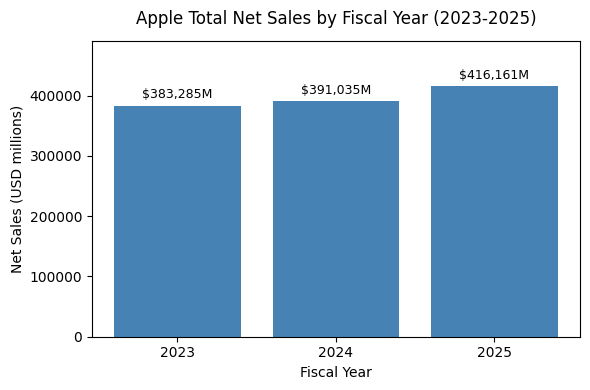

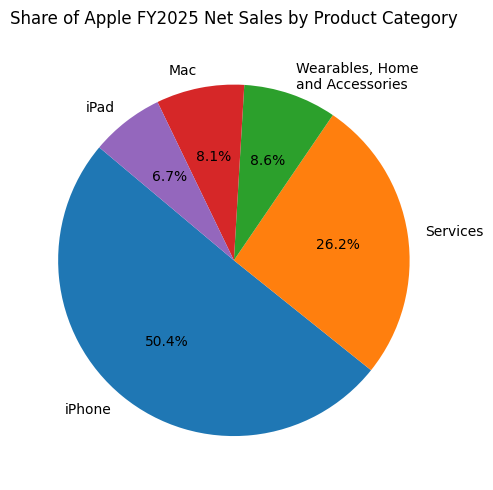

In [12]:
# 1. Bar Chart: Total Net Sales by Fiscal Year (2023-2025)
sales_by_year = agent_results["Q1"]["values_by_year"]
years = sorted(sales_by_year.keys())
revenues = [sales_by_year[y] for y in years]

trend_chart_path = os.path.join(OUTPUT_DIR, "apple_revenue_trend_chart.png")

plt.figure(figsize=(6, 4))
bars = plt.bar([str(y) for y in years], revenues, color="steelblue")
plt.title("Apple Total Net Sales by Fiscal Year (2023-2025)", pad=12)
plt.xlabel("Fiscal Year")
plt.ylabel("Net Sales (USD millions)")
plt.ylim(0, max(revenues) * 1.18)
plt.bar_label(bars, labels=[f"${v:,}M" for v in revenues], padding=3, fontsize=9)
plt.tight_layout()
plt.savefig(trend_chart_path, dpi=150, bbox_inches="tight", pad_inches=0.2)
plt.show()
plt.close()

# 2. Pie Chart: Share of FY2025 Net Sales by Product Category
cat_revenues = agent_results["Q2"]["calc_result"]["revenues"]
cat_labels = [
    "Wearables, Home\nand Accessories" if k == "Wearables, Home and Accessories" else k
    for k in cat_revenues.keys()
]
cat_values = list(cat_revenues.values())

pie_chart_path = os.path.join(OUTPUT_DIR, "apple_category_pie_chart.png")

plt.figure(figsize=(6.5, 5))
plt.pie(cat_values, labels=cat_labels, autopct="%1.1f%%", startangle=140)
plt.title("Share of Apple FY2025 Net Sales by Product Category", pad=12)
plt.tight_layout()
plt.savefig(pie_chart_path, dpi=150, bbox_inches="tight", pad_inches=0.2)
plt.show()
plt.close()

## Section 11: Final PDF Report Generation and Verification

This section compiles the final financial analysis report (`apple_financial_analysis_report_S21324.pdf`) using `fpdf2` in the exact four-section structure of the reference Medical Document Agent (Summary, Financial Data Tables, Charts, and Supporting Evidence), and verifies that all required figures, citations, and embedded charts are present.

In [13]:
def clean_text(text: str) -> str:
    """Sanitize Unicode characters so Helvetica (Latin-1) renders cleanly in fpdf2."""
    replacements = {
        "\u2013": "-",
        "\u2014": "-",
        "\u2018": "'",
        "\u2019": "'",
        "\u201c": '"',
        "\u201d": '"',
        "\u2022": "*",
        "\u00a0": " ",
    }
    for old, new in replacements.items():
        text = text.replace(old, new)
    return text.encode("latin-1", "replace").decode("latin-1")


pdf_path = os.path.join(OUTPUT_DIR, "apple_financial_analysis_report_S21324.pdf")

pdf = FPDF()
pdf.set_auto_page_break(auto=True, margin=15)
pdf.add_page()

# Title Header
pdf.set_font("Helvetica", "B", 16)
pdf.cell(
    0,
    10,
    clean_text("Apple Inc. Financial Analysis Report (FY2023-FY2025)"),
    new_x=XPos.LMARGIN,
    new_y=YPos.NEXT,
    align="C",
)
pdf.set_font("Helvetica", "", 10)
pdf.cell(
    0,
    6,
    clean_text("CSC3173: Artificial Intelligence (2024/25) - PA02 | Student Index Number: S/21/324"),
    new_x=XPos.LMARGIN,
    new_y=YPos.NEXT,
    align="C",
)
pdf.ln(5)

# 1. Summary (Q1, Q2, Q3 Agent Narratives)
pdf.set_font("Helvetica", "B", 12)
pdf.cell(0, 8, "1. Summary", new_x=XPos.LMARGIN, new_y=YPos.NEXT)

for q_id in ("Q1", "Q2", "Q3"):
    q_text = QUESTIONS[q_id]["question"]
    ans_text = agent_results[q_id]["report"]
    pdf.set_font("Helvetica", "B", 10)
    pdf.multi_cell(0, 6, clean_text(f"{q_id}: {q_text}"), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.set_font("Helvetica", "", 10)
    pdf.multi_cell(0, 5.5, clean_text(ans_text), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.ln(3)

# 2. Financial Data Tables (pdf.table)
pdf.set_font("Helvetica", "B", 12)
pdf.cell(0, 8, "2. Financial Data by Year & Category", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.ln(2)

# Table 2.1: Total Net Sales (2023-2025)
q1_vals = agent_results["Q1"]["values_by_year"]
q1_calc = agent_results["Q1"]["calc_result"]
pdf.set_font("Helvetica", "B", 10)
pdf.cell(0, 6, "Table 2.1: Total Net Sales (USD millions)", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_font("Helvetica", "", 10)
with pdf.table(col_widths=(40, 55, 95)) as table:
    row = table.row()
    row.cell("Fiscal Year")
    row.cell("Total Net Sales ($M)")
    row.cell("Source")
    for yr in sorted(q1_vals.keys()):
        r = table.row()
        r.cell(f"FY{yr}")
        r.cell(f"${q1_vals[yr]:,}")
        r.cell(clean_text(f"{q1_calc['source']} (p.{q1_calc['page']})"))
    r = table.row()
    r.cell("2023-2025 Change")
    r.cell(f"+${q1_calc['absolute_change']:,.0f} (+{q1_calc['percent_change']:.2f}%)")
    r.cell("Calculated in Python")
pdf.ln(4)

# Table 2.2: FY2025 Product Category Revenue Share
q2_calc = agent_results["Q2"]["calc_result"]
pdf.set_font("Helvetica", "B", 10)
pdf.cell(0, 6, "Table 2.2: FY2025 Net Sales by Product Category", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_font("Helvetica", "", 10)
with pdf.table(col_widths=(90, 50, 50)) as table:
    row = table.row()
    row.cell("Product Category")
    row.cell("FY2025 Net Sales ($M)")
    row.cell("Share of Total (%)")
    for cat, rev in q2_calc["revenues"].items():
        r = table.row()
        r.cell(clean_text(cat))
        r.cell(f"${rev:,}")
        r.cell(f"{q2_calc['shares'][cat]:.2f}%")
    r = table.row()
    r.cell("Total Net Sales")
    r.cell(f"${q2_calc['total']:,}")
    r.cell("100.00%")
pdf.ln(4)

# Table 2.3: Products vs. Services Growth (FY2024-FY2025)
q3_calc = agent_results["Q3"]["calc_result"]
p_c = q3_calc["products"]
s_c = q3_calc["services"]
pdf.set_font("Helvetica", "B", 10)
pdf.cell(0, 6, "Table 2.3: Products vs. Services Growth (FY2024-FY2025)", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_font("Helvetica", "", 10)
with pdf.table(col_widths=(45, 36, 36, 38, 35)) as table:
    row = table.row()
    row.cell("Segment")
    row.cell("FY2024 ($M)")
    row.cell("FY2025 ($M)")
    row.cell("Change ($M)")
    row.cell("Growth (%)")
    for seg_name, sc in (("Products", p_c), ("Services", s_c)):
        r = table.row()
        r.cell(seg_name)
        r.cell(f"${sc['old']:,}")
        r.cell(f"${sc['new']:,}")
        r.cell(f"+${sc['absolute_change']:,.0f}")
        r.cell(f"+{sc['percent_change']:.2f}%")
pdf.ln(6)

# 3. Charts (Bar Chart + Pie Chart)
pdf.set_font("Helvetica", "B", 12)
pdf.cell(0, 8, "3. Charts", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.ln(2)

if os.path.exists(trend_chart_path):
    pdf.image(trend_chart_path, w=125)
    pdf.ln(3)

if os.path.exists(pie_chart_path):
    pdf.image(pie_chart_path, w=100)
    pdf.ln(4)

# 4. Supporting Evidence (Exact Cited 10-K Chunks for Q1, Q2, Q3)
pdf.set_font("Helvetica", "B", 12)
pdf.cell(0, 8, "4. Supporting Evidence", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_font("Helvetica", "", 9)

seen_ev = set()
for q_id in ("Q1", "Q2", "Q3"):
    ch = agent_results[q_id]["calc_result"]["matched_chunk"]
    key = (ch["source"].lstrip("_"), ch["year"], ch["page"])
    if key in seen_ev:
        continue
    seen_ev.add(key)
    snippet = clean_text(ch["text"][:280].replace("\n", " "))
    line = f"[{ch['source'].lstrip('_')} ({ch['year']}) p.{ch['page']}] {snippet}..."
    pdf.multi_cell(0, 5, clean_text(line), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.ln(2)

pdf.output(pdf_path)
print("PDF report saved to:", pdf_path)

PDF report saved to: /content/apple_financial_analysis_report_S21324.pdf


In [14]:
assert os.path.isfile(trend_chart_path), "Bar chart missing!"
assert os.path.isfile(pie_chart_path), "Pie chart missing!"
assert os.path.isfile(pdf_path) and os.path.getsize(pdf_path) > 0, "PDF report missing or empty!"

with fitz.open(pdf_path) as doc:
    full_pdf_text = "\n".join(page.get_text("text") for page in doc)
    print(f"PDF verified: {len(doc)} pages, {os.path.getsize(pdf_path):,} bytes.")

checks = {
    "FY2023 Total Net Sales": "383,285",
    "FY2024 Total Net Sales": "391,035",
    "FY2025 Total Net Sales": "416,161",
    "Q1 Growth (8.58%)": "8.58%",
    "Q2 Top Category (iPhone)": "iPhone",
    "Q2 iPhone Revenue": "209,586",
    "Q3 Products Growth (4.12%)": "4.12%",
    "Q3 Services Growth (13.51%)": "13.51%",
    "Section 1 Summary": "1. Summary",
    "Section 2 Tables": "2. Financial Data",
    "Section 3 Charts": "3. Charts",
    "Section 4 Evidence": "4. Supporting Evidence",
}

for label, token in checks.items():
    status = "PASS" if token in full_pdf_text else "FAIL"
    print(f"[{status}] {label}")

PDF verified: 3 pages, 87,991 bytes.
[PASS] FY2023 Total Net Sales
[PASS] FY2024 Total Net Sales
[PASS] FY2025 Total Net Sales
[PASS] Q1 Growth (8.58%)
[PASS] Q2 Top Category (iPhone)
[PASS] Q2 iPhone Revenue
[PASS] Q3 Products Growth (4.12%)
[PASS] Q3 Services Growth (13.51%)
[PASS] Section 1 Summary
[PASS] Section 2 Tables
[PASS] Section 3 Charts
[PASS] Section 4 Evidence
